# Week 8 - K-Nearest Neighbors
## Dataset: NOAA Storm Events

This week covers k-nearest neighbors (KNN) and the distance metrics it depends on. KNN does not fit a model in the usual sense. To classify a new event, it finds the k training events closest to it in feature space and predicts the share of those neighbors that reported damage. Everything therefore depends on what "closest" means, which is set by the distance metric (Euclidean, Manhattan, and others) and by how each feature is scaled before distances are measured. The number of neighbors k controls overfitting. With k = 1 the prediction copies a single neighbor, and with a very large k every event gets close to the overall average.

The question is the same one Weeks 4 to 9 asked of Storm Events, whether a 2017 event reported any property damage, with the same features and the same split that keeps whole storm episodes out of training. KNN is a sharp test of that split. A model that predicts from its nearest neighbors will look excellent whenever the nearest neighbor is a sibling event from the same storm, so this notebook measures how often that happens and what it does to the scores.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold, StratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, RocCurveDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Data, features, and splits

The features are the starting latitude and longitude, the month, the log of event duration, and indicators for the eight most common event types, exactly as in Weeks 4 to 9. The test set is 7,961 events from storm episodes that never appear in training. Logistic regression and a random forest with the Week 6 settings are refit as reference points, at test ROC-AUCs of 0.821 and 0.917.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['logDuration'] = np.log10(((end - begin).dt.total_seconds() / 3600).clip(lower=0) + 0.1)
data['month'] = begin.dt.month
type_cols = []
for t in data['EVENT_TYPE'].value_counts().head(8).index:
    col = 'type_' + t.replace(' ', '')
    data[col] = (data['EVENT_TYPE'] == t).astype(int)
    type_cols.append(col)
data = data.dropna(subset=['month', 'logDuration']).reset_index(drop=True)
numeric = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration']
features = numeric + type_cols
X = data[features]
y = data['damaged'].values
groups = data['EPISODE_ID'].values

# Same episode-grouped split as Weeks 4 to 6
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]

# A validation set of whole episodes carved out of the training events
fit_pos, val_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1).split(X_train, y_train, g_train))
X_fit, X_val, y_fit, y_val = X_train.iloc[fit_pos], X_train.iloc[val_pos], y_train[fit_pos], y_train[val_pos]
print('Events used:', len(data), '| share with damage reported:', round(y.mean(), 3))
print('Training events:', len(train_idx), f'(fit {len(fit_pos)}, validation {len(val_pos)})', '| test events:', len(test_idx))
print('Episodes shared between fit and validation:', len(set(g_train[fit_pos]) & set(g_train[val_pos])),
      '| between training and test:', len(set(g_train) & set(groups[test_idx])))

prep = ColumnTransformer([('num', StandardScaler(), numeric), ('types', 'passthrough', type_cols)])
logit = Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=400, max_features=6, min_samples_leaf=3, n_jobs=-1,
                                random_state=0).fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]
p_forest = forest.predict_proba(X_test)[:, 1]
print(f'Reference test ROC-AUC, logistic regression: {roc_auc_score(y_test, p_logit):.4f}')
print(f'Reference test ROC-AUC, Week 6 random forest settings: {roc_auc_score(y_test, p_forest):.4f}')

Events used: 31863 | share with damage reported: 0.347
Training events: 23902 (fit 19402, validation 4500) | test events: 7961
Episodes shared between fit and validation: 0 | between training and test: 0


Reference test ROC-AUC, logistic regression: 0.8212
Reference test ROC-AUC, Week 6 random forest settings: 0.9165


### Neighbors from the same storm

The first cell checks how often an event's nearest neighbor in the training set comes from its own storm episode. It then tunes k twice, once with ordinary random 5-fold cross-validation and once with folds grouped by episode. Features are standardized in both cases.

Nearest neighbor comes from the same storm episode: 0.667
Nearest neighbor has the same damage label, same episode: 0.888 | different episode: 0.809



  k  Random-fold CV ROC-AUC  Episode-grouped CV ROC-AUC  Overstatement
  1                  0.8396                      0.7731         0.0666
  3                  0.9058                      0.8366         0.0692
  5                  0.9188                      0.8532         0.0656
 10                  0.9239                      0.8638         0.0601
 15                  0.9213                      0.8657         0.0557
 25                  0.9147                      0.8667         0.0481
 50                  0.8989                      0.8641         0.0348
100                  0.8810                      0.8561         0.0249
200                  0.8627                      0.8457         0.0170
Best k by Random-fold CV ROC-AUC: 10
Best k by Episode-grouped CV ROC-AUC: 25


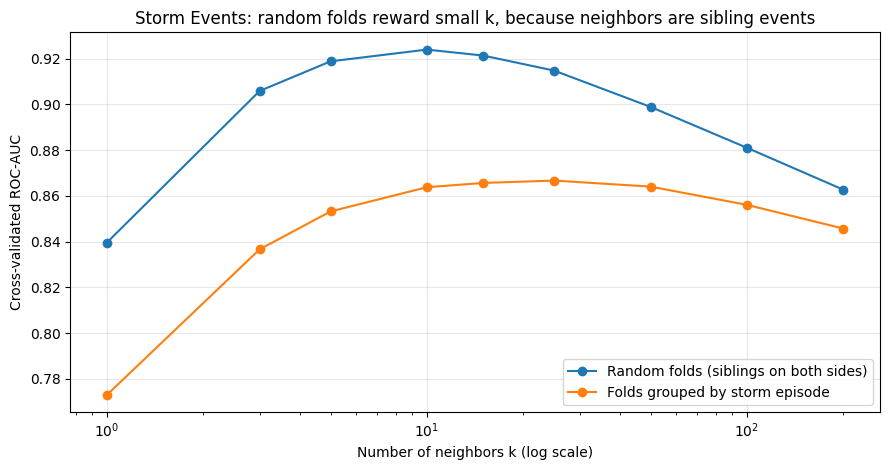

In [3]:
# For each training event, find its nearest other training event in standardized feature space
Z_train = StandardScaler().fit_transform(X_train)
idx = NearestNeighbors(n_neighbors=2).fit(Z_train).kneighbors(Z_train, return_distance=False)[:, 1]
same_episode = g_train[idx] == g_train
same_label = y_train[idx] == y_train
print(f'Nearest neighbor comes from the same storm episode: {same_episode.mean():.3f}')
print(f'Nearest neighbor has the same damage label, same episode: {same_label[same_episode].mean():.3f}'
      f' | different episode: {same_label[~same_episode].mean():.3f}')

random_cv = StratifiedKFold(5, shuffle=True, random_state=0)
grouped_cv = GroupKFold(5)
k_rows = []
for k in [1, 3, 5, 10, 15, 25, 50, 100, 200]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    k_rows.append({'k': k,
                   'Random-fold CV ROC-AUC': cross_val_score(model, X_train, y_train, cv=random_cv, scoring='roc_auc').mean(),
                   'Episode-grouped CV ROC-AUC': cross_val_score(model, X_train, y_train, cv=grouped_cv, groups=g_train,
                                                                 scoring='roc_auc').mean()})
k_table = pd.DataFrame(k_rows)
k_table['Overstatement'] = k_table['Random-fold CV ROC-AUC'] - k_table['Episode-grouped CV ROC-AUC']
print()
print(k_table.round(4).to_string(index=False))
for col in ['Random-fold CV ROC-AUC', 'Episode-grouped CV ROC-AUC']:
    print(f'Best k by {col}: {int(k_table.loc[k_table[col].idxmax(), "k"])}')
best_k = int(k_table.loc[k_table['Episode-grouped CV ROC-AUC'].idxmax(), 'k'])

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(k_table['k'], k_table['Random-fold CV ROC-AUC'], marker='o', label='Random folds (siblings on both sides)')
ax.plot(k_table['k'], k_table['Episode-grouped CV ROC-AUC'], marker='o', label='Folds grouped by storm episode')
ax.set_xscale('log')
ax.set_xlabel('Number of neighbors k (log scale)')
ax.set_ylabel('Cross-validated ROC-AUC')
ax.set_title('Storm Events: random folds reward small k, because neighbors are sibling events')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Two thirds of training events (0.667) have a nearest neighbor from their own episode. Those neighbors share the damage label 88.8% of the time, against 80.9% for neighbors from a different storm, so a sibling is an unusually good guide to the answer. That is exactly what random folds reward. Random cross-validation picks k = 10 and scores it at 0.924, while folds grouped by episode pick k = 25 and score it at 0.867. The overstatement is largest for small k (0.067 at k = 1) and shrinks as k grows (0.017 at k = 200), because a prediction from many neighbors depends less on any one sibling. The grouped curve is the honest one, and its shape is the usual trade-off between bias and variance. Small k overfits to individual events, large k smooths across too many dissimilar ones, and the best value lies in between.

### Feature scaling

A distance adds up the differences in every feature, so a feature measured on a larger scale counts for more. The next cell shows each feature's spread and compares four scaling choices at k = 25, along with the share of the average squared distance that comes from the single largest feature.

In [4]:
def grouped_auc(model, X_use=None):
    X_use = X_train if X_use is None else X_use
    return cross_val_score(model, X_use, y_train, cv=grouped_cv, groups=g_train, scoring='roc_auc').mean()


spread = pd.DataFrame({'Standard deviation': X_train.std(), 'Range': X_train.max() - X_train.min()})
print('Spread of each feature before scaling:')
print(spread.round(3).to_string())

scaling_rows = []
for name, scaler in [('No scaling', None), ('Standardized', StandardScaler()), ('Min-max', MinMaxScaler()),
                     ('Robust (median and IQR)', RobustScaler())]:
    knn = KNeighborsClassifier(n_neighbors=best_k)
    Z = X_train.values if scaler is None else scaler.fit_transform(X_train)
    var = Z.var(axis=0)
    share = pd.Series(var / var.sum(), index=features)
    scaling_rows.append({'Scaling': name,
                         'Episode-grouped CV ROC-AUC': grouped_auc(knn if scaler is None else make_pipeline(scaler, knn)),
                         'Largest share of distance': share.idxmax(), 'Its share': share.max()})
print(f'\nKNN with k = {best_k} and Euclidean distance')
print(pd.DataFrame(scaling_rows).round(4).to_string(index=False))

Spread of each feature before scaling:
                             Standard deviation    Range
BEGIN_LAT                                 5.115   74.836
BEGIN_LON                                11.671  106.084
month                                     2.317   11.000
logDuration                               0.719    3.872
type_ThunderstormWind                     0.491    1.000
type_Hail                                 0.428    1.000
type_FlashFlood                           0.324    1.000
type_Flood                                0.264    1.000
type_Tornado                              0.208    1.000
type_MarineThunderstormWind               0.199    1.000
type_HeavyRain                            0.195    1.000
type_Lightning                            0.108    1.000



KNN with k = 25 and Euclidean distance
                Scaling  Episode-grouped CV ROC-AUC Largest share of distance  Its share
             No scaling                      0.8624                 BEGIN_LON     0.8060
           Standardized                      0.8667           type_FlashFlood     0.0833
                Min-max                      0.8531     type_ThunderstormWind     0.2913
Robust (median and IQR)                      0.8700               logDuration     0.5221


Without scaling, longitude supplies 81% of the squared distance, because its standard deviation is 11.7 degrees against 0.7 for log duration and at most 0.5 for the event type indicators. The model then finds neighbors mostly by longitude and scores 0.862. Standardizing gives every feature the same variance, so each supplies 8.3% of the distance, and the score rises to 0.867. Min-max scaling does worst (0.853). Outlying events in Alaska, American Samoa, and offshore stretch the latitude and longitude ranges, so the mainland is squeezed into a narrow band and the thunderstorm wind indicator ends up supplying 29% of the distance, the same problem found in Week 4. Robust scaling (subtracting the median and dividing by the interquartile range) does slightly best (0.870). It leaves the 0/1 indicators unscaled and divides log duration by its narrow middle range, so duration supplies 52% of the distance, which suggests duration deserves more weight than standardization gives it.

### Distance metrics and neighbor weighting

The Minkowski distance of order p is the p-th root of the sum of each absolute feature difference raised to the power p. With p = 2 it is the familiar Euclidean distance, with p = 1 it is the Manhattan distance (the sum of the absolute differences), and as p grows it approaches the Chebyshev distance, which only counts the single largest difference. Cosine distance ignores length altogether and compares only the direction of two standardized events from the center of the data. The next cell compares these metrics at k = 25, each with uniform weights (every neighbor counts equally) and distance weights (closer neighbors count more).

Standardized features, k = 25
Weights                  distance  uniform
Metric                                    
Euclidean (p = 2)          0.8779   0.8667
Manhattan (p = 1)          0.8820   0.8715
Minkowski p = 4            0.8755   0.8642
Chebyshev (largest gap)    0.8719   0.8598
Cosine (angle only)        0.8798   0.8666


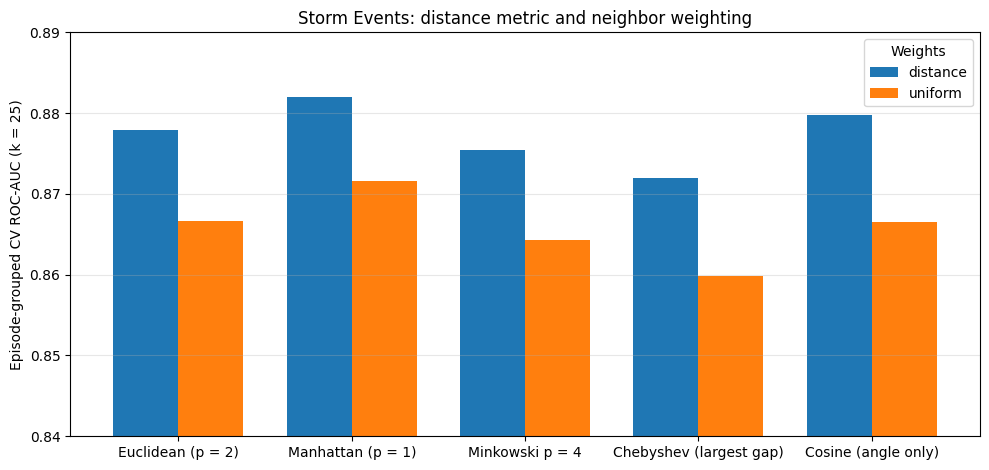

In [5]:
metrics = [('Euclidean (p = 2)', dict(metric='euclidean')), ('Manhattan (p = 1)', dict(metric='manhattan')),
           ('Minkowski p = 4', dict(metric='minkowski', p=4)), ('Chebyshev (largest gap)', dict(metric='chebyshev')),
           ('Cosine (angle only)', dict(metric='cosine'))]
metric_rows = []
for name, params in metrics:
    for weights in ['uniform', 'distance']:
        model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, weights=weights, **params))
        metric_rows.append({'Metric': name, 'Weights': weights, 'Episode-grouped CV ROC-AUC': grouped_auc(model)})
metric_table = pd.DataFrame(metric_rows)
pivot = metric_table.pivot(index='Metric', columns='Weights', values='Episode-grouped CV ROC-AUC').loc[[m for m, _ in metrics]]
print(f'Standardized features, k = {best_k}')
print(pivot.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 4.8))
pivot.plot.bar(ax=ax, rot=0, width=0.75)
ax.set_ylim(0.84, 0.89)
ax.set_ylabel(f'Episode-grouped CV ROC-AUC (k = {best_k})')
ax.set_xlabel('')
ax.set_title('Storm Events: distance metric and neighbor weighting')
ax.legend(title='Weights')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Distance weighting helps every metric, by 0.010 to 0.013, because it lets the closest neighbors, which are the most similar events, outweigh the ones at the edge of the neighborhood. Manhattan distance with distance weights does best (0.882), then cosine (0.880) and Euclidean (0.878). Chebyshev does worst (0.872 weighted, 0.860 uniform), since it looks only at the single largest difference and ignores whether two events agree on everything else. Within the Minkowski family the ranking follows p. The smaller p is, the less one large difference dominates, and with 12 features that are each only partly informative, it pays to let many small agreements add up.

### Measuring distance on the map

Latitude and longitude are angles on a sphere, and a degree of longitude covers less ground the farther north an event is. The haversine distance measures the great-circle distance between two points directly. The next cell compares KNN using only location under haversine and under plain Euclidean distance on degrees, and then KNN without location and with all features.

In [6]:
R_train = np.radians(X_train[['BEGIN_LAT', 'BEGIN_LON']].values)
geo_rows = [
    ('Location only, haversine (great-circle km)',
     grouped_auc(KNeighborsClassifier(n_neighbors=best_k, metric='haversine', algorithm='ball_tree'), R_train)),
    ('Location only, Euclidean on raw degrees',
     grouped_auc(KNeighborsClassifier(n_neighbors=best_k), X_train[['BEGIN_LAT', 'BEGIN_LON']])),
    ('Event type, month, and duration, no location',
     grouped_auc(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)), X_train.drop(columns=['BEGIN_LAT', 'BEGIN_LON']))),
    ('All 12 features', grouped_auc(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))))]
print(pd.DataFrame(geo_rows, columns=['Neighbors found by', 'Episode-grouped CV ROC-AUC']).round(4).to_string(index=False))
print(f'\nKilometers per degree of longitude at 25, 37.5, and 48 degrees north: '
      f'{", ".join(f"{111.32 * np.cos(np.radians(lat)):.0f}" for lat in [25, 37.5, 48])}')

                          Neighbors found by  Episode-grouped CV ROC-AUC
  Location only, haversine (great-circle km)                      0.8057
     Location only, Euclidean on raw degrees                      0.8061
Event type, month, and duration, no location                      0.7825
                             All 12 features                      0.8667

Kilometers per degree of longitude at 25, 37.5, and 48 degrees north: 101, 88, 74


Location alone predicts damage reports with a grouped ROC-AUC of 0.806, and the haversine distance makes no practical difference (0.806 against 0.806). Across the continental United States a degree of longitude shrinks from about 101 km to 74 km, but each event's neighbors lie within a small area where that ratio barely changes, so the ranking of neighbors stays almost the same. Without location, event type, month, and duration reach 0.783, and all 12 features together reach 0.867, so location and event type carry different information. Location matters this much because, as Week 4 found, damage reporting practice differs by forecast office.

### Tuning with grouped and random folds

The last step searches the scaler, k, the metric, and the weighting together with `GridSearchCV`, 60 combinations in all, once with random folds and once with folds grouped by episode, and checks each winner on the test episodes.

In [7]:
pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {'scale': [StandardScaler(), RobustScaler()],
              'knn__n_neighbors': [10, 25, 50, 75, 100],
              'knn__metric': ['euclidean', 'manhattan', 'cosine'],
              'knn__weights': ['uniform', 'distance']}
searches = {}
for label, cv, groups in [('Random folds', random_cv, None), ('Episode-grouped folds', grouped_cv, g_train)]:
    t0 = time.time()
    searches[label] = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=cv, n_jobs=6).fit(X_train, y_train, groups=groups)
    print(f'{label}: {len(searches[label].cv_results_["params"])} settings x 5 folds took {time.time() - t0:.0f} seconds')

search = searches['Episode-grouped folds']
res = pd.DataFrame(search.cv_results_)
res['scale'] = res['param_scale'].astype(str).str.replace('()', '', regex=False)
cols = ['scale', 'param_knn__n_neighbors', 'param_knn__metric', 'param_knn__weights', 'mean_test_score', 'std_test_score']
print('\nTop settings with episode-grouped folds:')
print(res.sort_values('rank_test_score')[cols].head(8).round(4).to_string(index=False))
print(f'Spread of grouped CV ROC-AUC across all settings: {res["mean_test_score"].min():.4f} to {res["mean_test_score"].max():.4f}')

compare = []
for label, s in searches.items():
    p = s.best_estimator_.predict_proba(X_test)[:, 1]
    compare.append({'Folds used for tuning': label, 'k chosen': s.best_params_['knn__n_neighbors'],
                    'Metric': s.best_params_['knn__metric'], 'Weights': s.best_params_['knn__weights'],
                    'Scaler': str(s.best_params_['scale']).replace('()', ''),
                    'CV ROC-AUC (the estimate)': s.best_score_, 'Test ROC-AUC (unseen episodes)': roc_auc_score(y_test, p)})
compare = pd.DataFrame(compare)
compare['Overstatement'] = compare['CV ROC-AUC (the estimate)'] - compare['Test ROC-AUC (unseen episodes)']
print()
print(compare.round(4).to_string(index=False))

Random folds: 60 settings x 5 folds took 94 seconds


Episode-grouped folds: 60 settings x 5 folds took 79 seconds

Top settings with episode-grouped folds:
         scale  param_knn__n_neighbors param_knn__metric param_knn__weights  mean_test_score  std_test_score
  RobustScaler                      50            cosine           distance           0.8844          0.0174
  RobustScaler                      50         manhattan           distance           0.8844          0.0164
  RobustScaler                      25         manhattan           distance           0.8843          0.0172
  RobustScaler                      75            cosine           distance           0.8839          0.0171
  RobustScaler                     100            cosine           distance           0.8833          0.0169
StandardScaler                      50            cosine           distance           0.8830          0.0177
StandardScaler                      75            cosine           distance           0.8828          0.0173
StandardScaler           


Folds used for tuning  k chosen    Metric  Weights         Scaler  CV ROC-AUC (the estimate)  Test ROC-AUC (unseen episodes)  Overstatement
         Random folds        25 manhattan distance StandardScaler                     0.9318                          0.8851         0.0467
Episode-grouped folds        50    cosine distance   RobustScaler                     0.8844                          0.8877        -0.0033


With grouped folds the best setting is robust scaling, k = 50, cosine distance, and distance weights, at a grouped CV ROC-AUC of 0.884. Its score on the unseen test episodes is 0.888, so the estimate was accurate, even 0.003 too low. The top five settings all use robust scaling and distance weights and fall within about 0.001 of each other, and the full range across the 60 settings is 0.853 to 0.884. Random folds chose a smaller neighborhood (k = 25, Manhattan distance, standardized) and promised 0.932, but that model scored 0.885 on unseen episodes, an overstatement of 0.047. Random folds did not pick a bad model here, but they reported a score the model could not deliver.

### Final evaluation on held-out storm episodes

Test events (unseen episodes): 7961
                                        Model  Accuracy  Balanced acc.     F1  Log loss  ROC-AUC
                               Majority class    0.6514         0.5000 0.0000    0.6466   0.5000
                          Logistic regression    0.7715         0.7438 0.6656    0.4982   0.8212
              Random forest (Week 6 settings)    0.8501         0.8208 0.7711    0.3474   0.9165
KNN, default (k = 5, Euclidean, standardized)    0.8140         0.7832 0.7186    0.9308   0.8677
                KNN, tuned with grouped folds    0.8200         0.7867 0.7238    0.4524   0.8877



                          Model  Random split AUC  Episode split AUC    Gap
                   KNN, default            0.9166             0.8677 0.0489
                     KNN, tuned            0.9251             0.8877 0.0373
Random forest (Week 6 settings)            0.9449             0.9165 0.0285


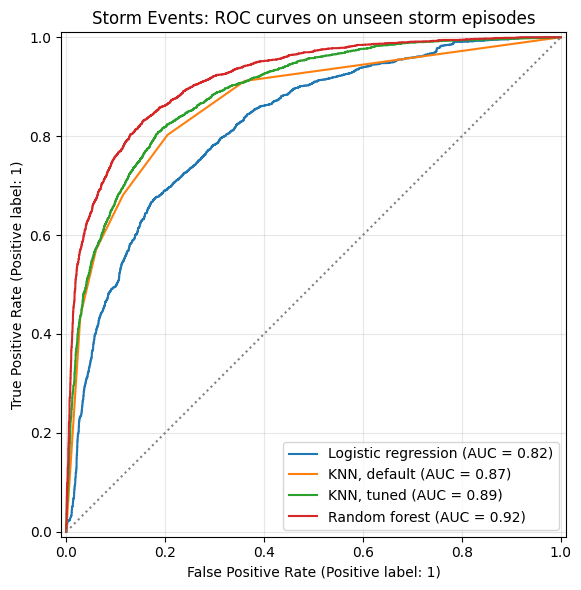

In [8]:
def scores(name, prob):
    pred = (prob >= 0.5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Balanced acc.': balanced_accuracy_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'Log loss': log_loss(y_test, np.clip(prob, 1e-6, 1 - 1e-6)),
            'ROC-AUC': roc_auc_score(y_test, prob)}


best = search.best_estimator_
p_best = best.predict_proba(X_test)[:, 1]
default_knn = make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(X_train, y_train)
p_default = default_knn.predict_proba(X_test)[:, 1]
final = pd.DataFrame([scores('Majority class', np.full(len(y_test), y_train.mean())),
                      scores('Logistic regression', p_logit),
                      scores('Random forest (Week 6 settings)', p_forest),
                      scores('KNN, default (k = 5, Euclidean, standardized)', p_default),
                      scores('KNN, tuned with grouped folds', p_best)])
print('Test events (unseen episodes):', len(y_test))
print(final.round(4).to_string(index=False))

# The same tuned model scored on a random split, where test events have siblings in training
r_train, r_test = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
gap_rows = []
for name, model, p_episode in [('KNN, default', make_pipeline(StandardScaler(), KNeighborsClassifier()), p_default),
                               ('KNN, tuned', search.best_estimator_, p_best),
                               ('Random forest (Week 6 settings)', RandomForestClassifier(n_estimators=400, max_features=6,
                                                                                          min_samples_leaf=3, n_jobs=-1,
                                                                                          random_state=0), p_forest)]:
    model.fit(X.iloc[r_train], y[r_train])
    gap_rows.append({'Model': name, 'Random split AUC': roc_auc_score(y[r_test], model.predict_proba(X.iloc[r_test])[:, 1]),
                     'Episode split AUC': roc_auc_score(y_test, p_episode)})
gap = pd.DataFrame(gap_rows)
gap['Gap'] = gap['Random split AUC'] - gap['Episode split AUC']
print()
print(gap.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 6))
for name, prob in [('Logistic regression', p_logit), ('KNN, default', p_default), ('KNN, tuned', p_best),
                   ('Random forest', p_forest)]:
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
ax.set_title('Storm Events: ROC curves on unseen storm episodes')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The tuned KNN reaches a test ROC-AUC of 0.888, with an accuracy of 0.820, a balanced accuracy of 0.787, and an F1 of 0.724. That beats logistic regression (0.821) and default KNN (0.868), but it falls short of the random forest (0.917). Default KNN has a log loss of 0.931, far worse than any other model, because with only 5 neighbors many events receive a predicted probability of exactly 0 or 1, and a confident wrong answer is heavily penalized. Tuning cut it to 0.452. Scored on a random split instead, tuned KNN reaches 0.925, a gap of 0.037 over its episode score, and the default's gap is 0.049. Both are larger than the random forest's gap of 0.029, so KNN leans on sibling events more than the forest does, which fits how it works.

## Discussion

### Overfitting

KNN overfits through k. With k = 1 each prediction copies one training event, the training score is perfect by construction, and the grouped CV ROC-AUC falls to 0.773. Two things kept that in check. The number of neighbors was chosen by cross-validation, which picked k = 25 to 50, and distance weighting let a larger neighborhood keep the advantage of its closest members. The larger risk was the evaluation itself. Two thirds of events have a sibling from their own storm as their nearest neighbor, so random folds overstated KNN by 0.048 to 0.069 for every k up to 25 and steered the search toward smaller neighborhoods. Grouping every fold and the test set by episode removed that, and the grouped estimate (0.884) matched the test score (0.888).

### Metrics and hyperparameter tuning

ROC-AUC was the main metric, as in earlier weeks, since 35% of events report damage and ROC-AUC does not depend on a single cutoff. Log loss was also reported because KNN's probabilities are shares of neighbors and can be exactly 0 or 1. The hyperparameters were tuned together by grid search with grouped 5-fold cross-validation, and each has a direct meaning for this problem.

- **k = 50** means each event is judged by the 50 most similar events from other storms.
- **Cosine distance** defines similarity by the pattern of an event's features, not by its distance from the center of the data.
- **Distance weights** give each neighbor a vote proportional to one over its distance, so near-identical events count most.
- **Robust scaling** sets how much each feature counts, and it gave duration more weight than standardization did.

The search was flat at the top, so the important choices were weighting by distance, avoiding min-max scaling and the Chebyshev metric, and keeping k well above 10.

### Expected or unexpected

I expected KNN to suffer from storm clustering more than earlier models, and it did, with the largest random split gap of any tuned model so far. I did not expect the overstatement to change which k looked best, from 25 to 10. I also expected the haversine distance to help, since it is the correct way to measure distance on the globe, but it changed nothing, because the neighbors are close enough that the curvature of the Earth does not matter. KNN finishing between logistic regression and the random forest was expected, since it can follow nonlinear patterns but treats every feature as equally important unless the scaling says otherwise.

### How EDA helped

The episode check from Week 4, where 64% of multi-event episodes share one damage label, predicted the main result here before any model was fit. The extreme latitude and longitude values found in Week 4 explained why min-max scaling failed again. The Module B finding that event duration is extremely right-skewed is why duration enters as a log, which is essential for any distance-based method, since raw hours would let a few multi-day floods dominate the distance.

### External sources

- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
- scikit-learn User Guide, "Nearest Neighbors," including the KD tree and ball tree algorithms: https://scikit-learn.org/stable/modules/neighbors.html
- scikit-learn API reference, `DistanceMetric`, which lists the Minkowski family, Chebyshev, and haversine distances: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.DistanceMetric.html
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.), Section 2.2.3 on K-nearest neighbors and the bias and variance trade-off.

### Conclusions

Tuned KNN predicts whether a 2017 storm event reported property damage with a test ROC-AUC of 0.888 on unseen storm episodes, ahead of logistic regression (0.821) but behind the random forest (0.917) and gradient boosting (0.920). Its most useful lesson is about evaluation. Because two thirds of events sit next to a sibling from the same storm, a model that predicts from neighbors looks far better on a random split than it is, and only folds grouped by episode give an honest estimate and the right k. Scaling and metric choices mattered more than in any earlier week, and distance weighting helped every metric.

For Milestone Two and the Capstone, KNN is not the strongest predictor, but it is a useful check. Its large random split gap measures how much any model could gain from recognizing storms instead of learning what causes damage, and it confirms that location carries much of the signal through reporting practice.